In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 17,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
r_all = []
pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
predict_data = sc.read_h5ad("../experiments/squidiff_plant_exp1_interception_predict_to_day_21.h5ad")
real_data = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")

r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print(r2, pearsonr)

# r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
# print(r2_new, pearson_new)
r_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
pearsonr_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])

# pd.DataFrame(r_all).to_csv(os.path.join("new_method_r_all_new.csv"))
# pd.DataFrame(pearsonr_all).to_csv(os.path.join("new_method_pearsonr_all_new.csv"))


# fig.savefig(os.path.join("fig2.pdf"), bbox_inches="tight")

# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')

-196090.9809464715 -0.0019572435299951697


72.517685 9.741589


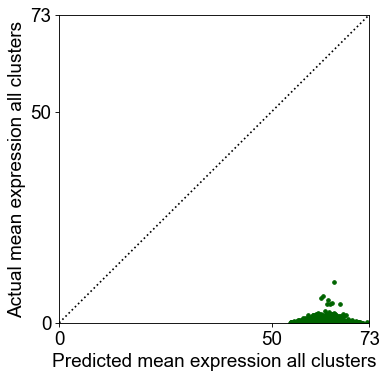

In [3]:
fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
plt.scatter(predict,
            real,
             s=10,
             c='darkgreen'
           )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit + 1, 50)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
plt.xlabel("Predicted mean expression all clusters")
plt.ylabel("Actual mean expression all clusters")
# fig.savefig(os.path.join("fig2.png"), bbox_inches="tight")
fig.savefig(os.path.join(f"pred_with_actual_exp1_fixed_all_cluster.pdf"), bbox_inches="tight")

# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')

0 -77941.51398861295 0.0024771451876535117
85.21704 21.482143
max 85.21704
cluster 0 done
1 -184241.26930273257 0.00042308863811595055
83.09681 4.2194448
max 83.09681
cluster 1 done
2 -229914.54136424532 -0.007883079770883634
86.64431 4.1046133
max 86.64431
cluster 2 done
3 -276691.13862299104 -0.004438327264841655
119.32644 3.8844335
max 119.32644
cluster 3 done
4 -219579.00077129272 0.004221264056659474
99.94425 4.2332034
max 99.94425
cluster 4 done
5 -252315.9986356891 -0.007525952337027093
108.21066 3.8949158
max 108.21066
cluster 5 done
6 -106842.58431714642 0.0007032286680093745
148.3426 3.998263
max 148.3426
cluster 6 done
7 -176573.99139530765 0.0017075120694311078
137.42773 12.8131485
max 137.42773
cluster 7 done
8 -211922.54782312107 -0.01148179810914661
119.39732 4.144558
max 119.39732
cluster 8 done
9 -168016.5943988038 -0.0017784152987368215
111.11095 4.216074
max 111.11095
cluster 9 done
10 -254985.84630638687 0.003915169230649664
123.409454 4.0117373
max 123.409454
clust

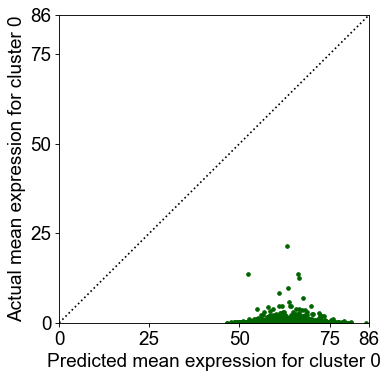

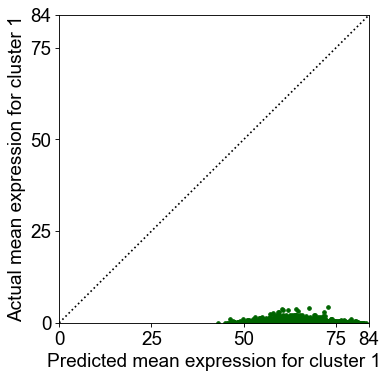

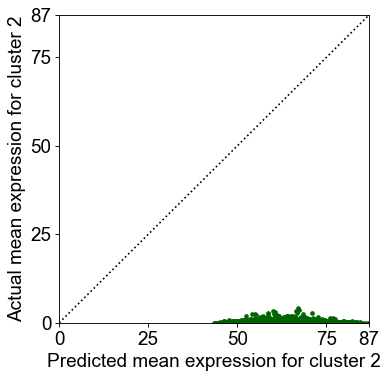

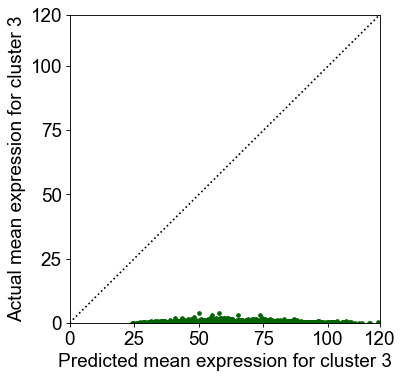

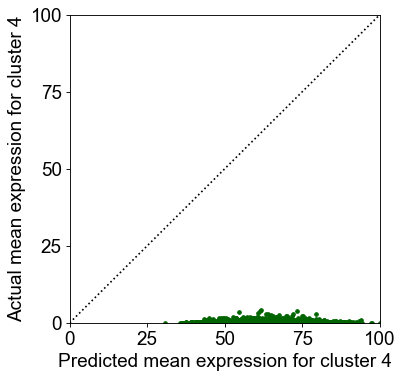

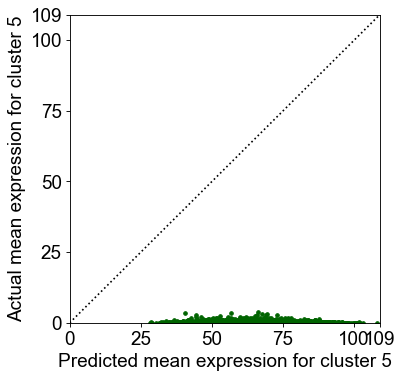

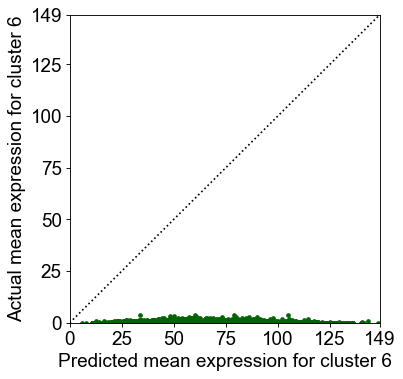

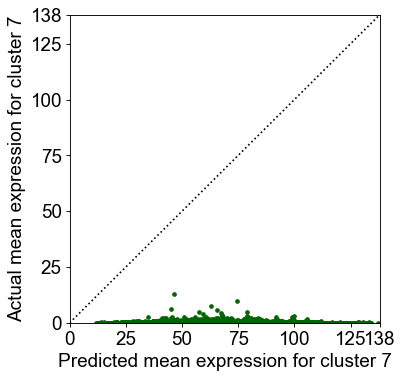

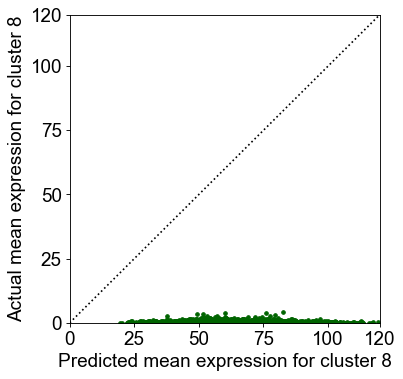

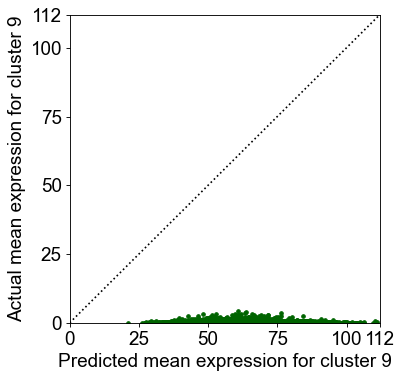

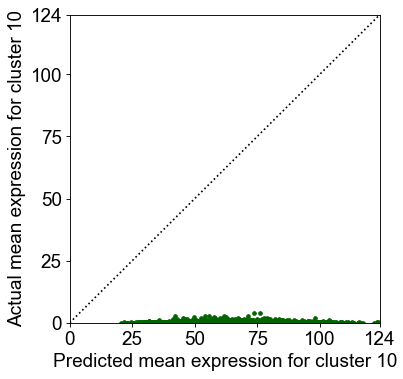

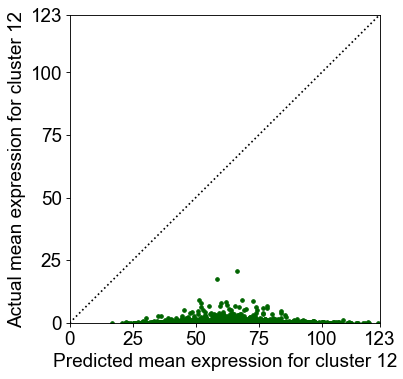

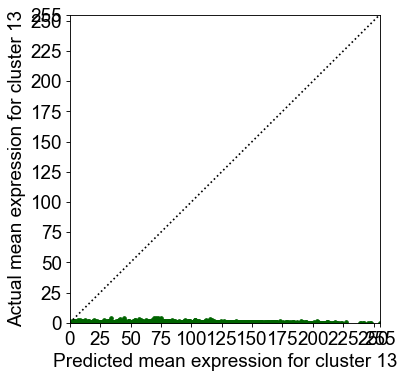

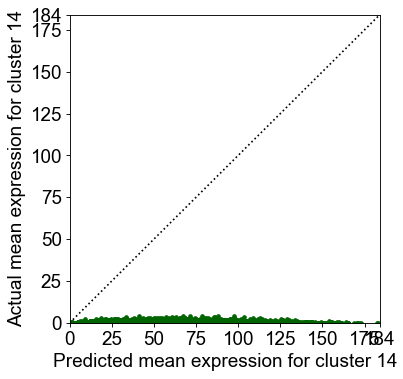

In [4]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
# r_all = []
# pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
for i in range(15):
  if i ==11:
    continue
  real_data = sc.read_h5ad(f"../../inputs/test_day21_plant_experiment1_cluster_{i}.h5ad")
  predict_data = sc.read_h5ad(f"../experiments/squidiff_plant_exp1_interception_predict_to_day_21_cluster_{i}.h5ad")

  # predict_data = sc.read_h5ad(f"../experiments/plants_experiment1_predict_day21_cluster{i}_fixed/interception_predict_to_day_21.h5ad")
  r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
  print(i, r2, pearsonr)
  # r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
  # print(r2_new, pearson_new)
  r_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
  pearsonr_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])


  pd.DataFrame(r_all).to_csv(os.path.join("our_method_plant_exp1_r_all.csv"))
  pd.DataFrame(pearsonr_all).to_csv(os.path.join("our_method_plant_exp1_pearsonr_all.csv"))

  fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
  plt.scatter(predict,
              real,
              s=10,
              c='darkgreen'
            )
  limit = np.ceil(max(np.max(predict), np.max(real)))
  print(np.max(predict),np.max(real))
  plt.plot([0, limit], [0, limit], color="black", linestyle=":")
  plt.xlim([0, limit])
  plt.ylim([0, limit])
  if limit <= 8:
    ticks = np.arange(0, limit + 1, 1)
  else:    
    ticks = np.arange(0, limit + 1, 25)
    
  ticks = np.append(ticks, limit)
  ticks = np.unique(ticks)
  plt.xticks(ticks)
  plt.yticks(ticks)
  print("max",max(np.max(predict), np.max(real)))
  plt.xlabel(f"Predicted mean expression for cluster {i}")
  plt.ylabel(f"Actual mean expression for cluster {i}")
  print(f"cluster {i} done")
  fig.savefig(os.path.join(f"pred_with_actual_exp1_fixed_cluster_{i}.pdf"), bbox_inches="tight")
  
  # fig.savefig(os.path.join("fig2.png"), bbox_inches="tight")

# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')